<a href="https://colab.research.google.com/github/DragonXDQ/week8-lab/blob/main/Lab_CNN_Image_Classification_solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML302 Deep Learning and Neural Networks
## Lab: Building and Training a CNN Image Classifier
### Per-class accuracy and error analysis on Fashion-MNIST and CIFAR-10

Amity University Tashkent, Department of Information Technology and Engineering

---

**What you will learn in this lab**

1. How to load an image dataset in PyTorch and look at it.
2. What the layers of a Convolutional Neural Network (CNN) do.
3. How to build, train and test a small CNN.
4. Why overall accuracy is not enough, and how to measure accuracy **for each class**.
5. How to use a **confusion matrix** and look at wrong predictions to understand the model's mistakes.

**How this lab is organised**

| Part | Duration | What happens |
|---|---|---|
| Session 1 | 60 min | Guided walkthrough on **Fashion-MNIST**. Follow along and run every cell. |
| Session 2 | 60 min | Graded exercises on **CIFAR-10** (100 marks, about 30 minutes of work). |

**Before you start:** if you use Google Colab, go to *Runtime > Change runtime type* and select **GPU**. Training will be much faster. The notebook also works on a normal CPU, just more slowly.

---
# SESSION 1: Guided Walkthrough (Fashion-MNIST)

Suggested timing for the walkthrough:

| Section | Topic | Time |
|---|---|---|
| 1 | Setup | 3 min |
| 2 | Loading and exploring the data | 10 min |
| 3 | How a CNN works (shapes demo) | 10 min |
| 4 | Building the model | 7 min |
| 5 | Training the model | 12 min |
| 6 | Overall accuracy and per-class accuracy | 8 min |
| 7 | Error analysis: confusion matrix and wrong predictions | 10 min |

## 1. Setup

We import the libraries we need:

- `torch` and `torch.nn`: the main PyTorch library and its neural network building blocks.
- `torchvision`: ready-made image datasets and image transformations.
- `DataLoader`: gives us the data in small groups called **batches**.
- `numpy` and `matplotlib`: numbers and plotting.
- `confusion_matrix` from scikit-learn: used in the error analysis part.

We also choose the **device**. If a GPU is available we use it (`cuda`), otherwise the CPU.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Fix the random seed so everyone gets similar results
torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


## 2. Loading and exploring the data

**Fashion-MNIST** is a dataset of small grey-scale pictures of clothing items.

- 60,000 training images and 10,000 test images
- Each image is **28 x 28 pixels** with **1 colour channel** (grey)
- There are **10 classes**: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot

### 2.1 Transforms

Before giving images to the network we apply two simple steps:

1. `ToTensor()` converts the picture into a PyTorch tensor and scales pixel values from 0..255 to **0..1**.
2. `Normalize((0.5,), (0.5,))` changes the range from 0..1 to **-1..1**, using the formula `(x - 0.5) / 0.5`. Networks usually train better when the inputs are centred around zero.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),                 # pixels 0..255  ->  0..1
    transforms.Normalize((0.5,), (0.5,))   # pixels 0..1    ->  -1..1
])

# download=True downloads the data the first time (it takes a few seconds)
train_data = torchvision.datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_data  = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

class_names = train_data.classes
print("Number of training images:", len(train_data))
print("Number of test images:    ", len(test_data))
print("Class names:", class_names)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 2.50MB/s]

Number of training images: 60000
Number of test images:     10000
Class names: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2.2 One single image

Each item in the dataset is a pair: **(image, label)**.

- The image shape is `[channels, height, width]`, so here `[1, 28, 28]`.
- The label is a number from 0 to 9. We use `class_names` to turn it into a word.

In [4]:
image, label = train_data[0]

print("Image shape:", image.shape)
print("Smallest pixel value:", image.min().item(), " Largest pixel value:", image.max().item())
print("Label number:", label, " Class name:", class_names[label])

Image shape: torch.Size([1, 28, 28])
Smallest pixel value: -1.0  Largest pixel value: 1.0
Label number: 9  Class name: Ankle boot


### 2.3 DataLoader and batches

We do not give the network one image at a time. We give it a **batch** (a group) of images. Here one batch has 64 images.

- `shuffle=True` for training: the order changes every epoch, which helps learning.
- `shuffle=False` for testing: we keep the order fixed. This is important later, because we will match each prediction with its original image.

The shape of a batch is `[batch_size, channels, height, width]`.

In [5]:
train_loader = DataLoader(train_data, batch_size=64,  shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))   # take the first batch
print("Batch of images:", images.shape)       # [64, 1, 28, 28]
print("Batch of labels:", labels.shape)       # [64]
print("First 10 labels:", labels[:10].tolist())

Batch of images: torch.Size([64, 1, 28, 28])
Batch of labels: torch.Size([64])
First 10 labels: [5, 7, 4, 7, 3, 8, 9, 5, 3, 1]


### 2.4 Looking at the images

The two helper functions below are used for the whole lab (also in Session 2):

- `to_image()` undoes the normalisation (from -1..1 back to 0..1) and changes the shape from `[C, H, W]` to `[H, W, C]`, which is the shape `matplotlib` expects.
- `show_images()` draws a row of images with their class names.

Both functions work for grey images (1 channel) and colour images (3 channels).

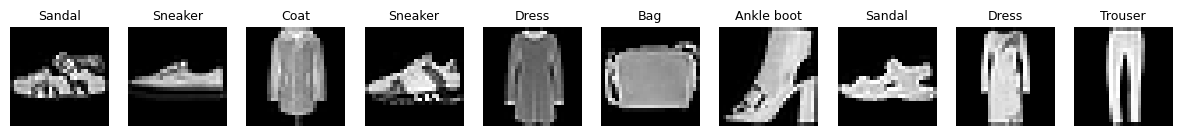

In [6]:
def to_image(tensor_image):
    img = tensor_image * 0.5 + 0.5          # undo Normalize: -1..1  ->  0..1
    img = img.permute(1, 2, 0).numpy()      # [C, H, W]  ->  [H, W, C]
    if img.shape[2] == 1:                   # grey image: remove the channel axis
        img = img[:, :, 0]
    return img


def show_images(images, labels, class_names, n=10):
    plt.figure(figsize=(15, 2.5))
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(to_image(images[i]), cmap="gray")
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis("off")
    plt.show()


show_images(images, labels, class_names)

### 2.5 How many images per class?

Before training, always check whether the classes are **balanced** (have a similar number of images). If one class had many more images, the model could become biased towards it. Fashion-MNIST is perfectly balanced: 6,000 training images per class.

In [7]:
counts = np.bincount(np.array(train_data.targets), minlength=len(class_names))

for name, count in zip(class_names, counts):
    print(f"{name:12s} {count}")

T-shirt/top  6000
Trouser      6000
Pullover     6000
Dress        6000
Coat         6000
Sandal       6000
Shirt        6000
Sneaker      6000
Bag          6000
Ankle boot   6000


/tmp/ipykernel_1346/1014983067.py:1: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  counts = np.bincount(np.array(train_data.targets), minlength=len(class_names))


## 3. How a CNN works

A normal fully connected network would flatten the 28 x 28 image into a long list of 784 numbers. It then forgets which pixels were next to each other. A **Convolutional Neural Network (CNN)** keeps the 2D structure of the image and learns small patterns such as edges, corners and textures.

The main building blocks:

| Layer | What it does | Effect on the shape |
|---|---|---|
| `Conv2d` | Slides small filters (for example 3 x 3) over the image. Each filter looks for one pattern and produces one **feature map**. | Changes the number of channels. With `padding=1` the height and width stay the same. |
| `ReLU` | Activation function: negative values become 0, positive values stay. | No change. |
| `MaxPool2d(2)` | Looks at every 2 x 2 block and keeps only the largest value. Makes the image smaller and keeps the strongest signals. | Height and width are divided by 2. |
| `Flatten` | Turns the 3D feature maps into one long vector. | `[C, H, W]` becomes `[C * H * W]`. |
| `Linear` | Normal fully connected layer. The last one gives one score per class. | Output size = number of classes. |

The idea: **convolution layers find features, linear layers make the final decision.**

### 3.1 Shapes demo

Let us pass one image through one convolution layer and one pooling layer, and print the shape after each step. The convolution layer below has **8 filters**, so it produces **8 feature maps**.

In [8]:
conv = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)
relu = nn.ReLU()
pool = nn.MaxPool2d(kernel_size=2)

x = images[:1]                       # one image, but keep the batch dimension
print("Input image:   ", x.shape)    # [1, 1, 28, 28]

x = conv(x)
print("After Conv2d:  ", x.shape)    # [1, 8, 28, 28]  -> 8 feature maps

x = relu(x)
print("After ReLU:    ", x.shape)    # same shape

x = pool(x)
print("After MaxPool: ", x.shape)    # [1, 8, 14, 14]  -> height and width halved

Input image:    torch.Size([1, 1, 28, 28])
After Conv2d:   torch.Size([1, 8, 28, 28])
After ReLU:     torch.Size([1, 8, 28, 28])
After MaxPool:  torch.Size([1, 8, 14, 14])


### 3.2 What do feature maps look like?

Below are the 8 feature maps for the same image. The filters are still **random** (the layer is not trained yet), but you can already see that each filter highlights the image in a different way. After training, the filters learn useful patterns such as edges.

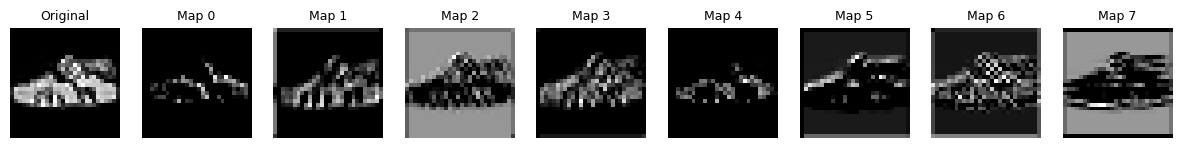

In [9]:
feature_maps = relu(conv(images[:1])).detach()   # shape [1, 8, 28, 28]

plt.figure(figsize=(15, 2.5))
plt.subplot(1, 9, 1)
plt.imshow(to_image(images[0]), cmap="gray")
plt.title("Original", fontsize=9)
plt.axis("off")

for i in range(8):
    plt.subplot(1, 9, i + 2)
    plt.imshow(feature_maps[0, i], cmap="gray")
    plt.title(f"Map {i}", fontsize=9)
    plt.axis("off")
plt.show()

## 4. Building the CNN model

Our model has **two convolution blocks** and **two linear layers**.

```
Input image                  1 x 28 x 28
Conv(1 -> 32) + ReLU        32 x 28 x 28
MaxPool                     32 x 14 x 14
Conv(32 -> 64) + ReLU       64 x 14 x 14
MaxPool                     64 x  7 x  7
Flatten                     64 * 7 * 7 = 3136 numbers
Linear(3136 -> 128) + ReLU  128
Linear(128 -> 10)           10 scores, one per class
```

In PyTorch, a model is a **class**:

- In `__init__` we **create** the layers.
- In `forward` we say **in which order** the data passes through the layers.

Pay attention to `nn.Linear(64 * 7 * 7, 128)`. The number `64 * 7 * 7` must match the shape after the last pooling layer. If the input image size changes, this number must change too. (You will need this in Session 2.)

In [10]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Block 1:  1 x 28 x 28  ->  32 x 14 x 14
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        # Block 2: 32 x 14 x 14  ->  64 x 7 x 7
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2)
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()

        # Classifier part
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)        # 10 classes

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # block 1
        x = self.pool(self.relu(self.conv2(x)))   # block 2
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)                           # raw scores (called "logits")
        return x


model = SimpleCNN().to(device)
print(model)

SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### 4.1 Check the model before training

Two quick checks that save a lot of time:

1. Give the model one batch and check the **output shape**. It should be `[batch_size, 10]`: 10 scores for every image.
2. Count the number of **trainable parameters** (weights and biases).

In [11]:
test_output = model(images.to(device))
print("Input shape: ", images.shape)
print("Output shape:", test_output.shape)    # expected: [64, 10]

num_params = sum(p.numel() for p in model.parameters())
print("Number of parameters:", num_params)

Input shape:  torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
Number of parameters: 421642


## 5. Training the model

### 5.1 Loss function and optimizer

- **Loss function**: `nn.CrossEntropyLoss()`. It measures how wrong the scores are compared with the true label. It is the standard loss for classification. (It applies softmax internally, so the model outputs raw scores.)
- **Optimizer**: `Adam` with learning rate `0.001`. It updates the weights to make the loss smaller.

### 5.2 The five steps of training

For every batch, training always follows the same five steps:

1. **Forward pass**: `outputs = model(images)`
2. **Compute the loss**: `loss = loss_fn(outputs, labels)`
3. **Clear old gradients**: `optimizer.zero_grad()`
4. **Backpropagation**: `loss.backward()` computes the gradients
5. **Update the weights**: `optimizer.step()`

One pass over the whole training set is called an **epoch**.

### 5.3 Training and evaluation functions

- `train_one_epoch()` runs the five steps for every batch and returns the average loss and the accuracy.
- `evaluate()` only measures loss and accuracy. It uses `model.eval()` and `torch.no_grad()` because we do **not** update weights on test data.
- `train_model()` repeats both for several epochs and saves the results in `history` so we can plot them.

We will use these same functions in Session 2.

In [12]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()                        # training mode
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)              # 1. forward pass
        loss = loss_fn(outputs, labels)      # 2. compute the loss
        optimizer.zero_grad()                # 3. clear old gradients
        loss.backward()                      # 4. backpropagation
        optimizer.step()                     # 5. update the weights

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)  # class with the highest score
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, loss_fn):
    model.eval()                         # evaluation mode
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():                # no gradients needed for testing
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


def train_model(model, train_loader, test_loader, num_epochs=5, learning_rate=0.001):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, loss_fn)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoch {epoch + 1}/{num_epochs} | "
              f"train loss {train_loss:.3f}, train acc {train_acc:.3f} | "
              f"test loss {test_loss:.3f}, test acc {test_acc:.3f}")
    return history

### 5.4 Train

Now we train for 5 epochs. On a GPU this takes about 1 minute; on a CPU a few minutes. While it runs, watch the numbers: the training loss should go **down** and the accuracy should go **up**.

In [13]:
model = SimpleCNN().to(device)     # create a fresh model
history = train_model(model, train_loader, test_loader, num_epochs=5)

Epoch 1/5 | train loss 0.436, train acc 0.844 | test loss 0.349, test acc 0.876
Epoch 2/5 | train loss 0.279, train acc 0.899 | test loss 0.284, test acc 0.895
Epoch 3/5 | train loss 0.232, train acc 0.915 | test loss 0.262, test acc 0.906
Epoch 4/5 | train loss 0.201, train acc 0.926 | test loss 0.251, test acc 0.912
Epoch 5/5 | train loss 0.176, train acc 0.935 | test loss 0.231, test acc 0.913


### 5.5 Learning curves

We plot loss and accuracy for every epoch.

- If **train** accuracy keeps going up but **test** accuracy stops improving or goes down, the model is starting to **overfit**: it memorises the training images instead of learning general patterns.
- If both are still improving, more epochs could help.

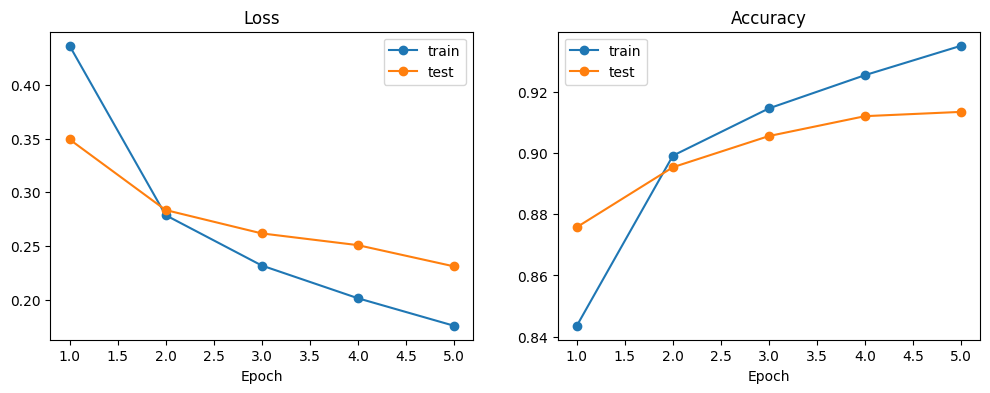

In [14]:
def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="train")
    plt.plot(epochs, history["test_loss"], marker="o", label="test")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], marker="o", label="train")
    plt.plot(epochs, history["test_acc"], marker="o", label="test")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.show()


plot_history(history)

## 6. Overall accuracy and per-class accuracy

### 6.1 Collect all predictions

To analyse the model we need three things for **every** test image:

- `y_true`: the true label
- `y_pred`: the predicted label
- `y_prob`: the probabilities for all 10 classes (we get them with `softmax`, which turns scores into numbers between 0 and 1 that add up to 1)

Because `test_loader` uses `shuffle=False`, position `i` in these arrays is the same image as `test_data[i]`.

In [15]:
def get_predictions(model, loader):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            probs = torch.softmax(outputs, dim=1)    # scores -> probabilities
            all_probs.append(probs.cpu())
            all_preds.append(probs.argmax(dim=1).cpu())
            all_labels.append(labels)

    y_true = torch.cat(all_labels).numpy()
    y_pred = torch.cat(all_preds).numpy()
    y_prob = torch.cat(all_probs).numpy()
    return y_true, y_pred, y_prob


y_true, y_pred, y_prob = get_predictions(model, test_loader)

overall_acc = (y_pred == y_true).mean()
print("Number of test images:", len(y_true))
print(f"Overall test accuracy: {overall_acc:.3f}")

Number of test images: 10000
Overall test accuracy: 0.913


### 6.2 Why overall accuracy is not enough

Overall accuracy is **one** number for the whole test set. It can hide problems. Imagine a model with 90% overall accuracy: it could be 99% correct on 9 classes and only 9% correct on the last class. For a real application (for example a medical system) that weak class could be the most important one.

So we compute the accuracy **separately for each class**:

```
accuracy of class c = (number of class-c images predicted correctly) / (number of class-c images)
```

In the code, `mask = (y_true == c)` is a list of True/False values: True for every test image whose real class is `c`. `y_pred[mask]` then keeps only the predictions for those images.

In [16]:
per_class_acc = []

print(f"{'Class':12s} {'Correct':>8s} {'Total':>6s} {'Accuracy':>9s}")
for c in range(len(class_names)):
    mask = (y_true == c)                     # images whose real class is c
    correct = (y_pred[mask] == c).sum()      # how many of them were predicted as c
    total = mask.sum()
    acc = correct / total
    per_class_acc.append(acc)
    print(f"{class_names[c]:12s} {correct:8d} {total:6d} {acc:9.3f}")

Class         Correct  Total  Accuracy
T-shirt/top       833   1000     0.833
Trouser           990   1000     0.990
Pullover          833   1000     0.833
Dress             916   1000     0.916
Coat              898   1000     0.898
Sandal            982   1000     0.982
Shirt             761   1000     0.761
Sneaker           981   1000     0.981
Bag               988   1000     0.988
Ankle boot        953   1000     0.953


### 6.3 Bar chart of per-class accuracy

The dashed line shows the overall accuracy. Classes **below** the line are the model's weak points.

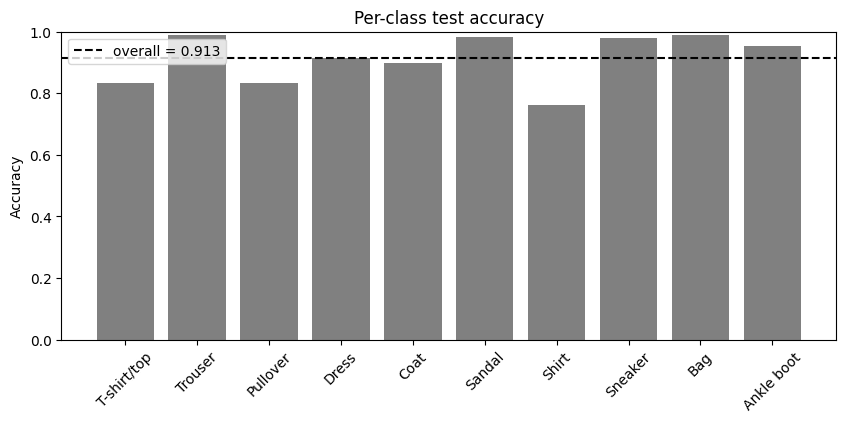

Three weakest classes:
  Shirt        0.761
  T-shirt/top  0.833
  Pullover     0.833


In [17]:
plt.figure(figsize=(10, 4))
plt.bar(class_names, per_class_acc, color="grey")
plt.axhline(overall_acc, color="black", linestyle="--", label=f"overall = {overall_acc:.3f}")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Per-class test accuracy")
plt.xticks(rotation=45)
plt.legend()
plt.show()

weakest = np.argsort(per_class_acc)[:3]     # indices of the 3 smallest accuracies
print("Three weakest classes:")
for c in weakest:
    print(f"  {class_names[c]:12s} {per_class_acc[c]:.3f}")

On Fashion-MNIST the weakest class is usually **Shirt**, followed by T-shirt/top, Pullover and Coat. The easiest classes are usually Trouser, Bag, Sandal and Sneaker, because their shapes are very different from the rest.

Per-class accuracy tells us **which** classes are weak. It does not tell us **what they are confused with**. For that we need the confusion matrix.

## 7. Error analysis

### 7.1 Confusion matrix

A confusion matrix is a 10 x 10 table:

- **Rows** = the true class
- **Columns** = the predicted class
- The number in row `i`, column `j` = how many images of true class `i` were predicted as class `j`

So:

- The **diagonal** (top-left to bottom-right) contains the **correct** predictions.
- Every number **outside the diagonal** is a **mistake**. A big number outside the diagonal means two classes are often confused.

In [18]:
cm = confusion_matrix(y_true, y_pred)
print(cm)

[[833   1  11  15   4   2 124   0   9   1]
 [  0 990   0   6   2   0   2   0   0   0]
 [ 12   0 833   8  76   0  71   0   0   0]
 [ 10   7   9 916  31   0  24   0   3   0]
 [  2   0  29  20 898   0  50   0   1   0]
 [  0   0   0   0   0 982   0  15   0   3]
 [ 94   2  30  35  72   0 761   0   6   0]
 [  0   0   0   0   0   6   0 981   0  13]
 [  3   0   0   4   1   2   0   2 988   0]
 [  0   0   0   0   0   7   1  39   0 953]]


A table of numbers is hard to read, so we draw it as an image. Darker cells mean bigger numbers.

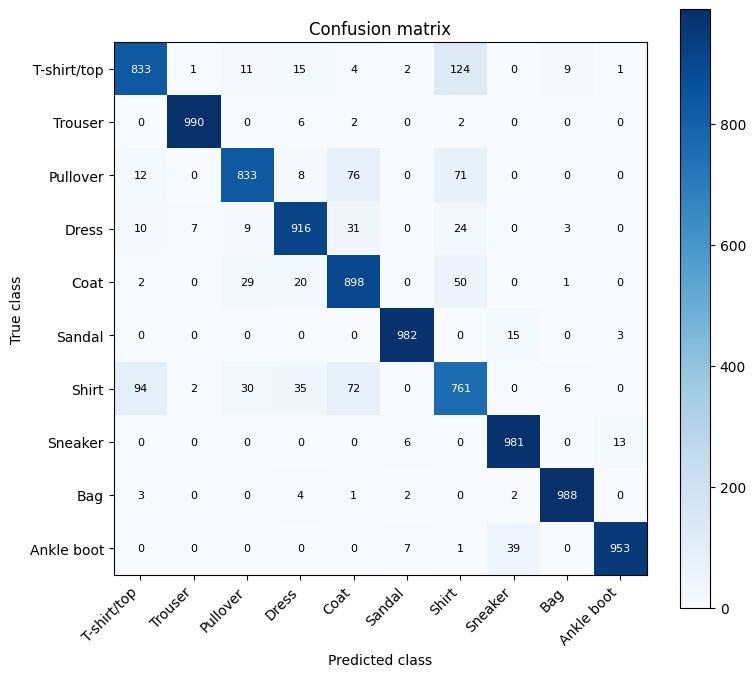

In [19]:
def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(8, 7))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()

    ticks = range(len(class_names))
    plt.xticks(ticks, class_names, rotation=45, ha="right")
    plt.yticks(ticks, class_names)
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title("Confusion matrix")

    # write the number inside every cell
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            colour = "white" if cm[i, j] > cm.max() / 2 else "black"
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color=colour)

    plt.tight_layout()
    plt.show()


plot_confusion_matrix(cm, class_names)

**Connection with per-class accuracy:** the per-class accuracy is simply the diagonal value divided by the sum of its row. Let us check that we get the same numbers as in Section 6.

In [20]:
acc_from_cm = cm.diagonal() / cm.sum(axis=1)

for name, a in zip(class_names, acc_from_cm):
    print(f"{name:12s} {a:.3f}")

T-shirt/top  0.833
Trouser      0.990
Pullover     0.833
Dress        0.916
Coat         0.898
Sandal       0.982
Shirt        0.761
Sneaker      0.981
Bag          0.988
Ankle boot   0.953


### 7.2 Which pairs of classes are confused the most?

We go through every cell outside the diagonal, store `(count, true class, predicted class)`, and sort from the largest count to the smallest.

In [21]:
pairs = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j:                                   # skip the diagonal
            pairs.append((cm[i, j], class_names[i], class_names[j]))

pairs.sort(reverse=True)                             # largest count first

print("Top 5 most common mistakes:")
for count, true_name, pred_name in pairs[:5]:
    print(f"  {count:4d} times: true '{true_name}' predicted as '{pred_name}'")

Top 5 most common mistakes:
   124 times: true 'T-shirt/top' predicted as 'Shirt'
    94 times: true 'Shirt' predicted as 'T-shirt/top'
    76 times: true 'Pullover' predicted as 'Coat'
    72 times: true 'Shirt' predicted as 'Coat'
    71 times: true 'Pullover' predicted as 'Shirt'


### 7.3 Looking at the wrong predictions

Numbers are useful, but the best way to understand mistakes is to **look at the images**. The function `plot_examples()` shows test images by their index, with the true label, the predicted label and (optionally) how confident the model was.

First, the indices of all wrong predictions:

Number of wrong predictions: 865


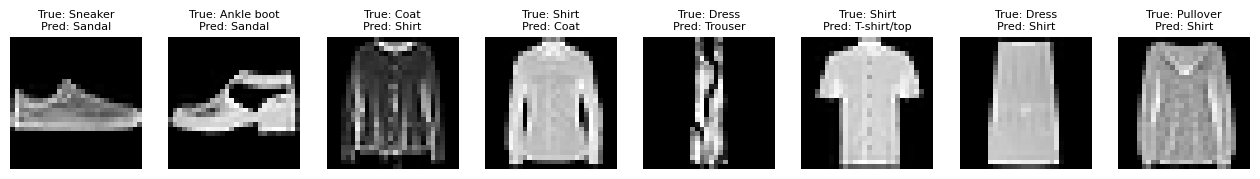

In [22]:
def plot_examples(dataset, indices, y_true, y_pred, class_names, y_prob=None):
    n = len(indices)
    plt.figure(figsize=(2 * n, 2.8))
    for k, idx in enumerate(indices):
        image, _ = dataset[idx]
        plt.subplot(1, n, k + 1)
        plt.imshow(to_image(image), cmap="gray")
        title = f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}"
        if y_prob is not None:
            title += f"\n({y_prob[idx].max():.2f})"
        plt.title(title, fontsize=8)
        plt.axis("off")
    plt.show()


wrong = np.where(y_pred != y_true)[0]          # indices of all mistakes
print("Number of wrong predictions:", len(wrong))

plot_examples(test_data, wrong[:8], y_true, y_pred, class_names)

### 7.4 Mistakes for one class

Now we look only at the mistakes for the **weakest class** (found in Section 6.3). We combine two conditions with `&` (AND): the true class is the weakest class, **and** the prediction is wrong.

Weakest class: Shirt
Number of mistakes for this class: 239


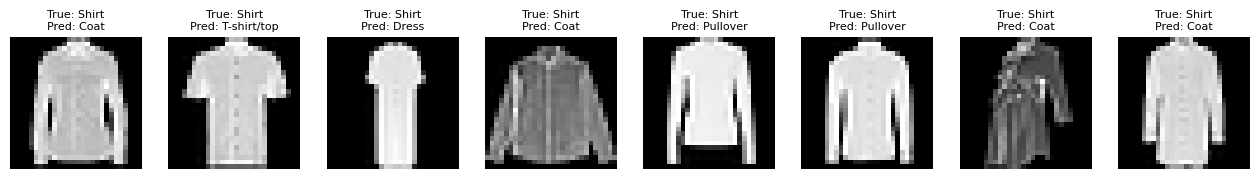

In [23]:
worst_class = weakest[0]
print("Weakest class:", class_names[worst_class])

wrong_in_class = np.where((y_true == worst_class) & (y_pred != y_true))[0]
print("Number of mistakes for this class:", len(wrong_in_class))

plot_examples(test_data, wrong_in_class[:8], y_true, y_pred, class_names)

### 7.5 Confident mistakes

Some mistakes happen when the model is unsure (for example 40% confidence). Those are less worrying. The dangerous mistakes are the ones where the model is **very sure and still wrong**. The number in brackets is the model's confidence (the highest probability).

`np.argsort(-confidence)` sorts from the most confident to the least confident.

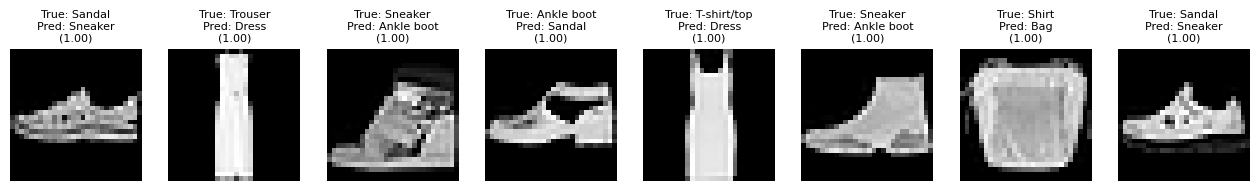

In [24]:
confidence = y_prob.max(axis=1)                   # how sure the model was, for every image

wrong_sorted = wrong[np.argsort(-confidence[wrong])]   # mistakes, most confident first
plot_examples(test_data, wrong_sorted[:8], y_true, y_pred, class_names, y_prob)

When you look at these images, ask yourself: **would a human also make this mistake?** Very often the answer is yes. At 28 x 28 pixels in grey, a shirt, a T-shirt, a pullover and a coat can look almost the same. Sometimes the label itself even looks wrong. Error analysis helps us decide what to do next:

- If the classes really look similar, we may need a **bigger model**, **more training** or **more data** for those classes.
- If the images are noisy or wrongly labelled, we may need to **clean the data**.
- If the model is very confident when wrong, we should be careful when using it in a real application.

## Session 1 summary

1. We loaded Fashion-MNIST, normalised it and checked that the classes are balanced.
2. We built a CNN with two convolution blocks and two linear layers, and checked the output shape.
3. We trained it with the five training steps and plotted the learning curves.
4. Overall accuracy gave one number; **per-class accuracy** showed which classes are weak.
5. The **confusion matrix** showed which classes are confused with each other.
6. **Looking at wrong images** helped us understand why.

### Preparing for Session 2: from Fashion-MNIST to CIFAR-10

| | Fashion-MNIST | CIFAR-10 |
|---|---|---|
| Image size | 28 x 28 | **32 x 32** |
| Channels | 1 (grey) | **3 (colour: red, green, blue)** |
| Content | clothing, plain background | animals and vehicles, real photos with backgrounds |
| Difficulty | easier | harder |

Think about which numbers in `SimpleCNN` must change for colour images of size 32 x 32.

---
# SESSION 2: Graded Exercises (CIFAR-10), 100 marks

### Rules

- Work **individually**. You have about **30 minutes**.
- You may use the functions from Session 1: `show_images`, `train_model`, `plot_history`, `get_predictions`, `plot_confusion_matrix`, `plot_examples`. **Run all Session 1 setup and function cells first** (Section 1 and every cell that defines a function). You do not need to retrain the Fashion-MNIST model.
- Replace every `____` with your code. Write your text answers in the cells marked **Your answer**.
- Marks for each part are shown in square brackets.

| Exercise | Topic | Marks |
|---|---|---|
| 1 | Adapt and train the CNN for CIFAR-10 | 30 |
| 2 | Overall and per-class accuracy | 35 |
| 3 | Error analysis | 35 |
| | **Total** | **100** |

### Setup (given, just run it)

CIFAR-10 has 60,000 colour images of size 32 x 32 in 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The normalisation now has **three** values because there are three colour channels.

In [ ]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))   # one value per colour channel
])

cifar_train = torchvision.datasets.CIFAR10(root="./data", train=True,  download=True, transform=cifar_transform)
cifar_test  = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=cifar_transform)

cifar_classes = cifar_train.classes
cifar_train_loader = DataLoader(cifar_train, batch_size=64,  shuffle=True)
cifar_test_loader  = DataLoader(cifar_test,  batch_size=256, shuffle=False)

print("Training images:", len(cifar_train), " Test images:", len(cifar_test))
print("Classes:", cifar_classes)

cifar_images, cifar_labels = next(iter(cifar_train_loader))
print("Batch shape:", cifar_images.shape)
show_images(cifar_images, cifar_labels, cifar_classes)

 37%|███▋      | 63.6M/170M [06:08<10:08, 176kB/s]

---
## Exercise 1: Adapt and train the CNN for CIFAR-10 [30 marks]

The model below has the same structure as `SimpleCNN` from Session 1, but some numbers are missing.

**(a) [15 marks]** Complete the model by replacing the three `____`:

- the number of **input channels** of `conv1` (colour images),
- the **input size** of `fc1` (hint: a 32 x 32 image goes through two `MaxPool2d(2)` layers; follow the shape comments),
- the number of **outputs** of `fc2`.

Then run the check cell. It must print an output shape of `[64, 10]`.

In [ ]:
class CifarCNN(nn.Module):
    def __init__(self):
        super().__init__()
        # Block 1:  3 x 32 x 32  ->  32 x 16 x 16
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        # Block 2: 32 x 16 x 16  ->  64 x ? x ?
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(kernel_size=2)
        self.relu = nn.ReLU()
        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [ ]:
# Check (given): the output shape must be [64, 10]
cifar_model = CifarCNN().to(device)
print("Output shape:", cifar_model(cifar_images.to(device)).shape)

**(b) [10 marks]** Train `cifar_model` for **3 epochs** with the `train_model()` function from Session 1, save the result in a variable called `cifar_history`, and plot the learning curves with `plot_history()`. Then write the final test accuracy in the answer cell.

In [ ]:
cifar_model = CifarCNN().to(device)

cifar_history = train_model(cifar_model, cifar_train_loader, cifar_test_loader, num_epochs=3)

# plot the learning curves
plot_history(cifar_history)

**Your answer:** The final test accuracy is printed after the third epoch and can also be checked with `cifar_history["test_acc"][-1]`.

**(c) [5 marks]** The same type of model reached about 90% on Fashion-MNIST but much less on CIFAR-10. Give **two** reasons why CIFAR-10 is harder.

**Your answer:** 1. CIFAR-10 contains colour images with more visual details, while Fashion-MNIST contains simple grayscale images. 2. Different CIFAR-10 classes can look similar, and objects can appear in different backgrounds and positions.

---
## Exercise 2: Overall and per-class accuracy [35 marks]

**(a) [10 marks]** Use `get_predictions()` to get `c_true`, `c_pred` and `c_prob` for the CIFAR-10 **test** set. Then compute and print the overall test accuracy.

In [ ]:
c_true, c_pred, c_prob = get_predictions(cifar_model, cifar_test_loader)

c_overall_acc = (c_pred == c_true).mean()
print(f"Overall CIFAR-10 test accuracy: {c_overall_acc:.3f}")

**(b) [15 marks]** Complete the function `per_class_accuracy()`. It must return a **list** with one accuracy value for each class. Use the same idea as Section 6.2 of Session 1 (a `mask` for each class). The print part is given.

In [ ]:
def per_class_accuracy(y_true, y_pred, num_classes):
    accuracies = []
    for c in range(num_classes):
        mask = (y_true == c)
        acc = (y_pred[mask] == y_true[mask]).mean()
        accuracies.append(acc)
    return accuracies


c_per_class = per_class_accuracy(c_true, c_pred, len(cifar_classes))

for name, acc in zip(cifar_classes, c_per_class):
    print(f"{name:12s} {acc:.3f}")

**(c) [10 marks]** Draw a bar chart of `c_per_class` with a dashed horizontal line at the overall accuracy (like Section 6.3). Then answer in the cell below: which class is the **best**, which is the **worst**, and give **one** possible reason why the worst class is difficult.

In [ ]:
plt.figure(figsize=(10, 4))
plt.bar(cifar_classes, c_per_class, color="grey")
plt.axhline(c_overall_acc, color="black", linestyle="--", label="overall")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("CIFAR-10 per-class test accuracy")
plt.xticks(rotation=45)
plt.legend()
plt.show()
print("Best class:", cifar_classes[int(np.argmax(c_per_class))])
print("Worst class:", cifar_classes[int(np.argmin(c_per_class))])

**Your answer:** The best and worst classes are printed by comparing the values in `c_per_class`. The worst class can be difficult because objects from different classes may have similar colours, shapes, or backgrounds.

---
## Exercise 3: Error analysis [35 marks]

**(a) [10 marks]** Compute the confusion matrix for CIFAR-10, save it as `c_cm`, and plot it with `plot_confusion_matrix()`.

In [ ]:
c_cm = confusion_matrix(c_true, c_pred)

plot_confusion_matrix(c_cm, cifar_classes)

**(b) [10 marks]** Print the **top 3** most confused pairs of classes (true class, predicted class, count). Use the same idea as Section 7.2 of Session 1: skip the diagonal, collect all pairs, sort from largest to smallest.

In [ ]:
c_pairs = []
for i in range(len(cifar_classes)):
    for j in range(len(cifar_classes)):
        if i != j:
            c_pairs.append((c_cm[i, j], cifar_classes[i], cifar_classes[j]))

c_pairs.sort(reverse=True)

print("Top 3 most common mistakes:")
for count, true_name, pred_name in c_pairs[:3]:
    print(f"  {count:4d} times: true '{true_name}' predicted as '{pred_name}'")

**(c) [10 marks]** Find the **worst class** from Exercise 2 automatically (hint: `np.argmin`). Then find the indices of the test images that **belong to this class but were predicted wrongly**, and show the first 8 of them with `plot_examples()` (include the confidence `c_prob`).

In [ ]:
c_worst = int(np.argmin(c_per_class))
print("Worst class:", cifar_classes[c_worst])

c_wrong = np.where((c_true == c_worst) & (c_pred != c_true))[0]
print("Number of mistakes for this class:", len(c_wrong))

plot_examples(cifar_test, c_wrong[:8], c_true, c_pred, cifar_classes, c_prob)

**(d) [5 marks]** Look at your confusion matrix and the wrong images. Suggest **one** change that could improve the accuracy of the worst class, and explain in one or two sentences why it would help.

**Your answer:** I would use data augmentation, such as random horizontal flips and small crops, during training. This gives the model more varied examples and may help it recognise the worst class in different positions and backgrounds.